# Retail Sales Exploratory Data Analysis (EDA)

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn  
**Dataset:** Synthetic retail sales data, ~505,000 orders (Jan 2023 - Dec 2025), 18 columns, intentionally messy

## Business Questions
1. Which products and categories drive the most revenue and profit?
2. How does demand change across months and seasons (festive, sale days, weekends)?
3. Which cities and payment methods matter most?
4. How do discounts affect profit margin?
5. How much revenue is lost to returns and cancellations?

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 13
os.makedirs("charts", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"charts/{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

df = pd.read_csv("retail_sales_data.csv")
print("Shape:", df.shape)
df.head()

Shape: (505000, 18)


,order_id,order_date,customer_id,customer_segment,product_id,product_name,category,unit_price,quantity,discount_pct,sales_amount,profit,payment_method,store_type,city,state,order_status,rating
0,ORD0400336,2023-01-03,CUST13207,Regular,1043,Football,Sports,483.38,2.0,30.0,676.73,-65.07,Cash on Delivery,Online,Mumbai,Maharashtra,Delivered,3.0
1,ORD0315673,10/09/2023,CUST26024,Regular,1023,Sugar 5kg,grocery,638.69,3.0,0.0,1916.07,822.27,UPI,Online,Hyderabad,Telangana,Delivered,5.0
2,ORD0217150,2024-10-06,CUST42323,Regular,1016,Basmati Rice 5kg,Grocery,220.79,2.0,15.0,375.34,123.68,UPI,Online,Lucknow,Uttar Pradesh,Delivered,NaN
3,ORD0177818,2023-11-02,CUST02600,Regular,1044,Badminton Racket,Sports,3319.29,1.0,15.0,2821.40,146.85,UPI,Offline,Hyderabad,Telangana,Delivered,4.0
4,ORD0375124,2023-08-08,CUST19384,Regular,1011,Hoodie,Clothing,3547.18,2.0,10.0,6384.92,2385.93,NaN,Offline,Pune,Maharashtra,Delivered,NaN


## 1. Data Understanding

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 505000 entries, 0 to 504999
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   order_id          505000 non-null  object 
 1   order_date        505000 non-null  object 
 2   customer_id       505000 non-null  object 
 3   customer_segment  489740 non-null  object 
 4   product_id        505000 non-null  int64  
 5   product_name      505000 non-null  object 
 6   category          505000 non-null  object 
 7   unit_price        505000 non-null  float64
 8   quantity          502549 non-null  float64
 9   discount_pct      494878 non-null  float64
 10  sales_amount      505000 non-null  float64
 11  profit            505000 non-null  float64
 12  payment_method    494857 non-null  object 
 13  store_type        505000 non-null  object 
 14  city              497443 non-null  object 
 15  state             505000 non-null  object 
 16  order_status      50

In [3]:
print("Duplicate rows:", df.duplicated().sum())
missing = pd.DataFrame({"missing": df.isna().sum(), "missing_%": (df.isna().mean()*100).round(2)})
missing[missing.missing > 0].sort_values("missing", ascending=False)

Duplicate rows: 5000


,missing,missing_%
rating,60722,12.02
customer_segment,15260,3.02
payment_method,10143,2.01
discount_pct,10122,2.00
city,7557,1.50
quantity,2451,0.49


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
product_id,505000.0,1025.11,15.66,1000.00,1011.00,1025.00,1043.00,1047.00
unit_price,505000.0,4904.00,10446.36,-54192.04,328.88,612.94,3213.40,54307.66
quantity,502549.0,2.44,3.92,1.00,1.00,2.00,3.00,199.00
discount_pct,494878.0,13.13,12.00,0.00,0.00,10.00,20.00,50.00
sales_amount,505000.0,8867.80,20343.64,30.02,583.40,1297.01,5948.42,162922.44
profit,505000.0,1723.05,5406.86,-55816.54,64.53,219.70,918.98,72406.21
rating,444278.0,3.94,1.12,1.00,3.00,4.00,5.00,5.00


## 2. Data Cleaning
Issues found: duplicate rows, mixed date formats, inconsistent text (case, extra spaces, `Bangalore` vs `Bengaluru`),
negative prices, extreme quantity outliers, and missing values in several columns.

In [5]:
raw_rows = len(df)

# 2.1 Remove exact duplicates
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {raw_rows - len(df):,}")

# 2.2 Standardise text columns
for c in ["product_name", "category", "city", "state", "payment_method", "customer_segment", "order_status", "store_type"]:
    df[c] = df[c].astype("string").str.strip()
df["category"] = df["category"].str.title().replace({"Home & Kitchen": "Home & Kitchen"})
df["city"] = df["city"].str.title().replace({"Bangalore": "Bengaluru"})
print("Categories:", sorted(df["category"].unique()))
print("Cities    :", sorted(df["city"].dropna().unique()))

# 2.3 Fix mixed date formats (YYYY-MM-DD and DD/MM/YYYY)
is_slash = df["order_date"].str.contains("/", na=False)
d1 = pd.to_datetime(df.loc[~is_slash, "order_date"], format="%Y-%m-%d")
d2 = pd.to_datetime(df.loc[is_slash, "order_date"], format="%d/%m/%Y")
df["order_date"] = pd.concat([d1, d2]).sort_index()
print("Date range:", df["order_date"].min().date(), "to", df["order_date"].max().date())

Duplicates removed: 5,000
Categories: ['Beauty', 'Clothing', 'Electronics', 'Grocery', 'Home & Kitchen', 'Sports']
Cities    : ['Ahmedabad', 'Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Jaipur', 'Kolkata', 'Lucknow', 'Mumbai', 'Noida', 'Patna', 'Pune']
Date range: 2023-01-01 to 2025-12-31


In [6]:
# 2.4 Negative prices -> absolute value (data entry sign error)
print("Negative prices:", (df["unit_price"] < 0).sum())
df["unit_price"] = df["unit_price"].abs()

# 2.5 Quantity outliers (IQR check, then business rule)
q1, q3 = df["quantity"].quantile([.25, .75]); iqr = q3 - q1
print("IQR upper fence:", q3 + 1.5*iqr, "| max quantity:", df["quantity"].max())
outlier_mask = df["quantity"] > 20      # a single retail order of >20 units is not realistic here
print("Quantity outliers (>20):", outlier_mask.sum())
df.loc[outlier_mask, "quantity"] = np.nan

# 2.6 Missing values
df["quantity"] = df["quantity"].fillna(df.groupby("product_id")["quantity"].transform("median"))
df["discount_pct"] = df["discount_pct"].fillna(0)                 # no discount recorded -> 0
for c in ["payment_method", "customer_segment", "city"]:
    df[c] = df[c].fillna("Unknown")
df["rated"] = df["rating"].notna()                                  # keep rating NaN, flag who rated
print("\nRemaining nulls:\n", df.isna().sum()[df.isna().sum() > 0])
print("Clean rows:", f"{len(df):,}")

Negative prices: 264
IQR upper fence: 6.0 | max quantity: 199.0
Quantity outliers (>20): 408



Remaining nulls:
 rating    60124
dtype: int64
Clean rows: 500,000


## 3. Feature Engineering

In [7]:
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["month_name"] = df["order_date"].dt.strftime("%b")
df["quarter"] = df["order_date"].dt.quarter
df["weekday"] = df["order_date"].dt.day_name()
df["is_weekend"] = df["order_date"].dt.dayofweek >= 5
df["profit_margin_%"] = (df["profit"] / df["sales_amount"] * 100).round(2)
df["season"] = np.select(
    [df.month.isin([10, 11]), df.month == 12, df.month.isin([4, 5, 6])],
    ["Festive (Oct-Nov)", "Year-end (Dec)", "Summer slump (Apr-Jun)"], default="Regular")

month_order = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

# Revenue analysis uses delivered orders only; returns/cancellations are analysed separately
delivered = df[df["order_status"] == "Delivered"].copy()
print(f"Delivered orders: {len(delivered):,} of {len(df):,}")

Delivered orders: 439,930 of 500,000


## 4. Exploratory Analysis

### 4.1 Key business metrics

In [8]:
kpi = {
    "Total orders": len(df),
    "Delivered orders": len(delivered),
    "Revenue (delivered)": delivered["sales_amount"].sum(),
    "Profit (delivered)": delivered["profit"].sum(),
    "Overall margin %": delivered["profit"].sum() / delivered["sales_amount"].sum() * 100,
    "Avg order value": delivered["sales_amount"].mean(),
    "Unique customers": df["customer_id"].nunique(),
    "Avg rating": df["rating"].mean(),
}
for k, v in kpi.items():
    print(f"{k:22s}: {v:>18,.2f}")

Total orders          :         500,000.00
Delivered orders      :         439,930.00
Revenue (delivered)   :   3,889,859,233.41
Profit (delivered)    :     755,577,486.36
Overall margin %      :              19.42
Avg order value       :           8,842.00
Unique customers      :          59,989.00
Avg rating            :               3.94


### 4.2 Revenue trend over time

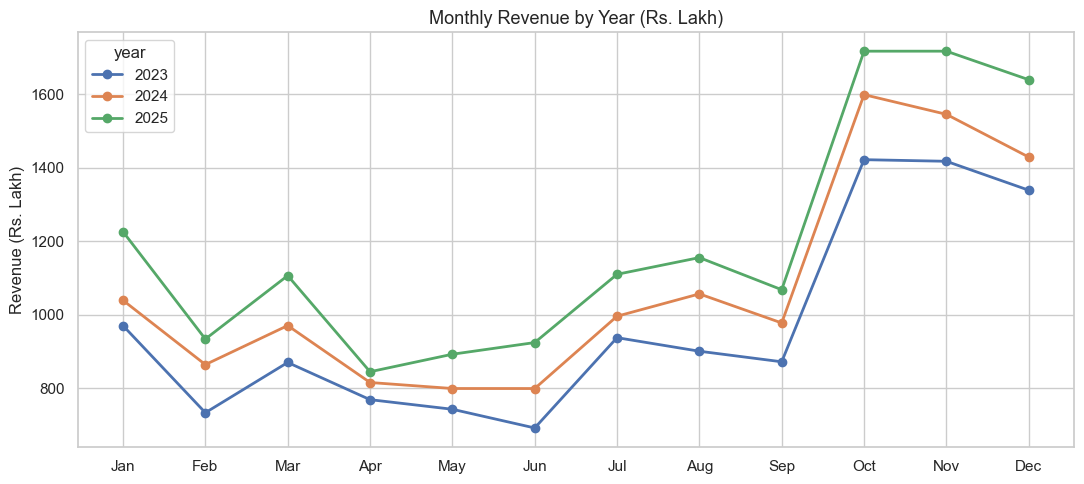

Revenue by year (Rs. Cr):
year
2023    116.68
2024    128.94
2025    143.37
Name: sales_amount, dtype: float64
YoY growth %:
year
2023     NaN
2024    10.5
2025    11.2
Name: sales_amount, dtype: float64


In [9]:
monthly = delivered.groupby(["year", "month"])["sales_amount"].sum().reset_index()
monthly["revenue_lakh"] = monthly["sales_amount"] / 1e5
pivot = monthly.pivot(index="month", columns="year", values="revenue_lakh")
ax = pivot.plot(marker="o", linewidth=2)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(month_order)
ax.set_title("Monthly Revenue by Year (Rs. Lakh)"); ax.set_xlabel(""); ax.set_ylabel("Revenue (Rs. Lakh)")
save("01_monthly_revenue_trend")

yearly = delivered.groupby("year")["sales_amount"].sum()
print("Revenue by year (Rs. Cr):"); print((yearly/1e7).round(2))
print("YoY growth %:"); print((yearly.pct_change()*100).round(1))

### 4.3 Seasonal demand

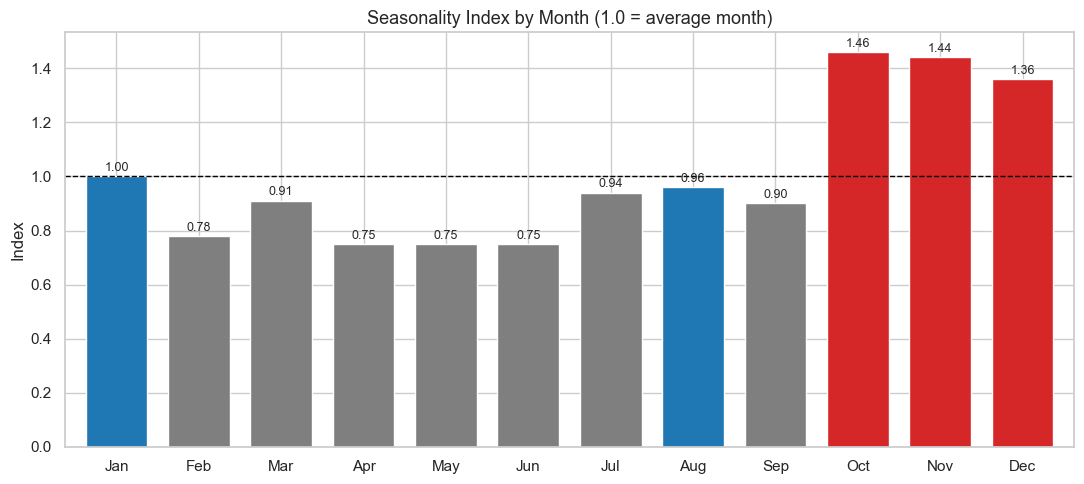

month
Jan    1.00
Feb    0.78
Mar    0.91
Apr    0.75
May    0.75
Jun    0.75
Jul    0.94
Aug    0.96
Sep    0.90
Oct    1.46
Nov    1.44
Dec    1.36
Name: sales_amount, dtype: float64


In [10]:
m = delivered.groupby("month")["sales_amount"].sum()
seasonal_index = (m / m.mean()).round(2)       # 1.00 = average month
colors = ["#d62728" if v > 1.15 else "#1f77b4" if v >= 0.95 else "#7f7f7f" for v in seasonal_index]
ax = seasonal_index.plot(kind="bar", color=colors, width=.75)
ax.axhline(1, color="black", ls="--", lw=1)
ax.set_xticklabels(month_order, rotation=0)
ax.set_title("Seasonality Index by Month (1.0 = average month)"); ax.set_xlabel(""); ax.set_ylabel("Index")
for i, v in enumerate(seasonal_index): ax.text(i, v + .02, f"{v:.2f}", ha="center", fontsize=9)
save("02_seasonality_index")
print(seasonal_index.rename(index=dict(enumerate(month_order, 1))))

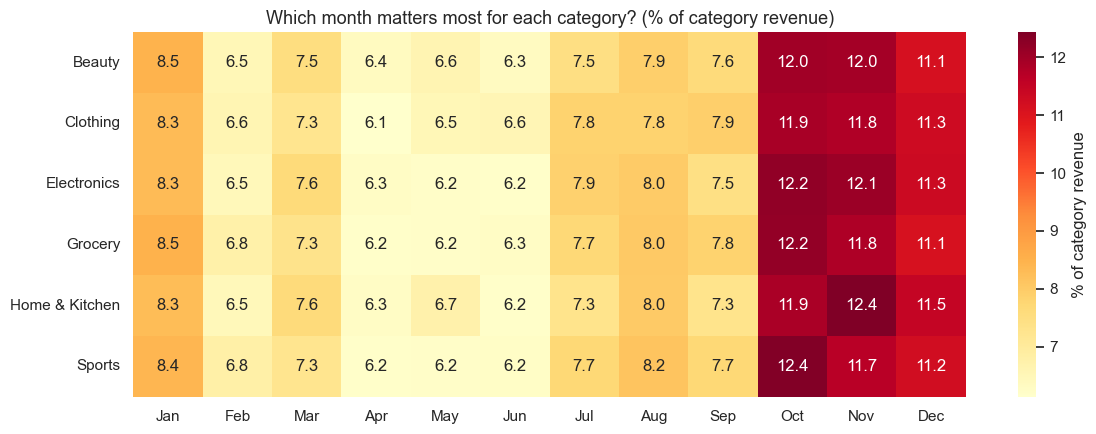

In [11]:
# Category x month heatmap (share of each category's annual revenue)
heat = delivered.pivot_table(index="category", columns="month", values="sales_amount", aggfunc="sum")
heat = heat.div(heat.sum(axis=1), axis=0) * 100
heat.columns = month_order
plt.figure(figsize=(12, 4.5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "% of category revenue"})
plt.title("Which month matters most for each category? (% of category revenue)"); plt.ylabel("")
save("03_category_month_heatmap")

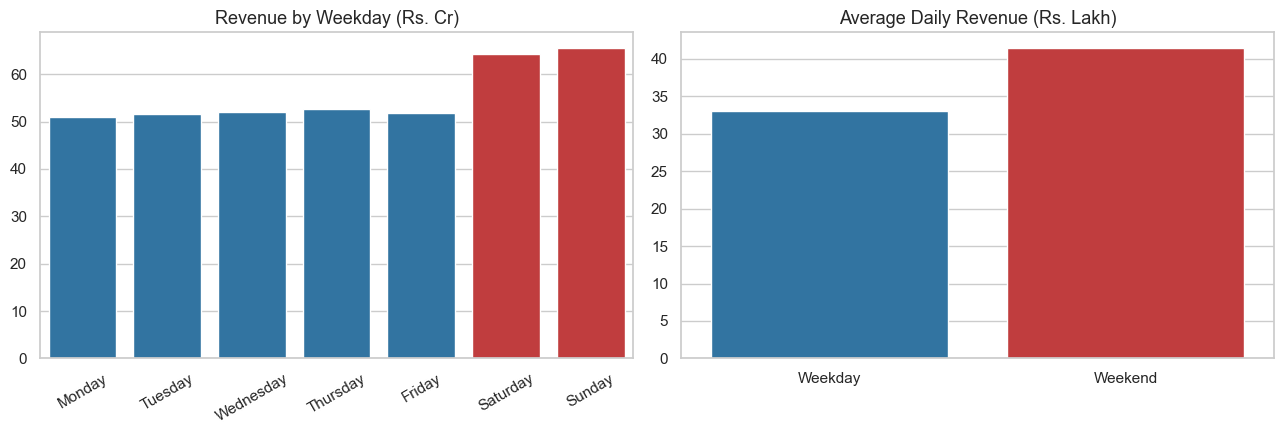

Weekend uplift in daily revenue: 25.3%


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
wd = delivered.groupby("weekday")["sales_amount"].sum().reindex(day_order) / 1e7
sns.barplot(x=wd.index, y=wd.values, ax=axes[0], palette=["#1f77b4"]*5 + ["#d62728"]*2)
axes[0].set_title("Revenue by Weekday (Rs. Cr)"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=30)

per_day = delivered.groupby(["order_date", "is_weekend"])["sales_amount"].sum().reset_index()
avg = per_day.groupby("is_weekend")["sales_amount"].mean() / 1e5
sns.barplot(x=["Weekday", "Weekend"], y=avg.values, ax=axes[1], palette=["#1f77b4", "#d62728"])
axes[1].set_title("Average Daily Revenue (Rs. Lakh)")
save("04_weekday_weekend")
print(f"Weekend uplift in daily revenue: {(avg[True]/avg[False]-1)*100:.1f}%")

### 4.4 Top products and categories

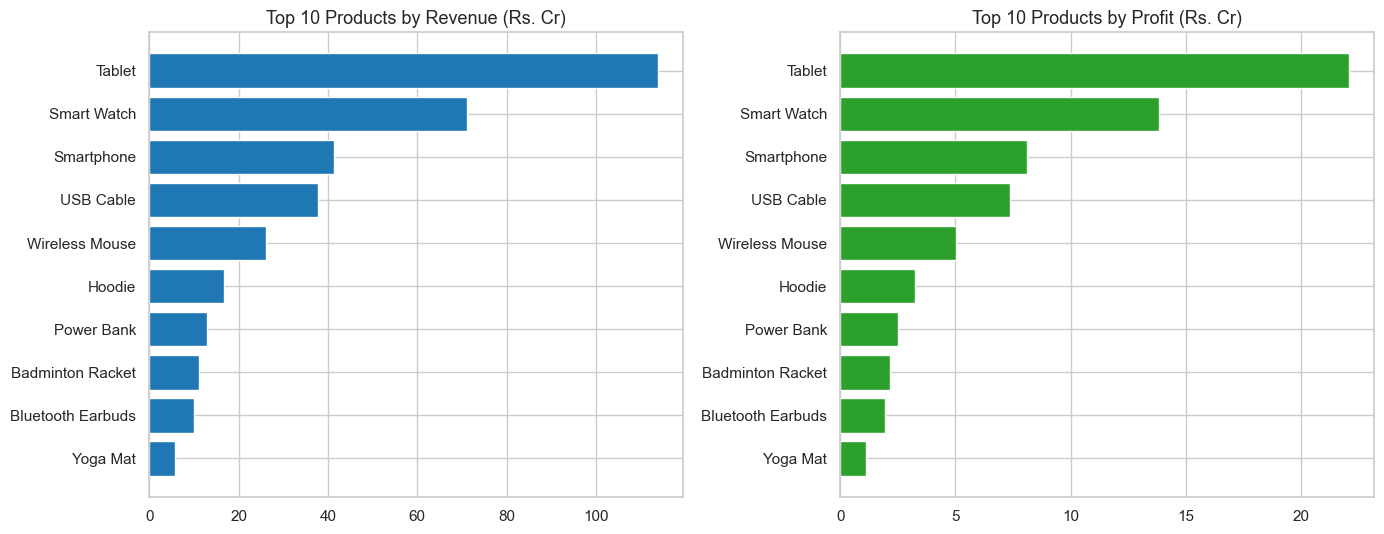

,product_name,category,revenue,profit,units,margin_%
41,Tablet,Electronics,1.137526e+09,220714953.2,24838.0,19.4
36,Smart Watch,Electronics,7.113876e+08,138510030.3,28892.0,19.5
37,Smartphone,Electronics,4.137099e+08,80929229.0,26267.0,19.6
43,USB Cable,Electronics,3.787189e+08,73927695.1,22583.0,19.5
45,Wireless Mouse,Electronics,2.614062e+08,50130969.8,17866.0,19.2
20,Hoodie,Clothing,1.680230e+08,32670048.0,53971.0,19.4
31,Power Bank,Electronics,1.303440e+08,25253177.6,12447.0,19.4
2,Badminton Racket,Sports,1.124957e+08,21787450.1,40107.0,19.4
6,Bluetooth Earbuds,Electronics,1.000757e+08,19320503.0,37610.0,19.3
47,Yoga Mat,Sports,5.668101e+07,11094947.6,20149.0,19.6


In [13]:
prod = delivered.groupby(["product_name", "category"]).agg(
    revenue=("sales_amount", "sum"), profit=("profit", "sum"), units=("quantity", "sum")).reset_index()
prod["margin_%"] = prod["profit"] / prod["revenue"] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
t = prod.nlargest(10, "revenue").sort_values("revenue")
axes[0].barh(t["product_name"], t["revenue"]/1e7, color="#1f77b4"); axes[0].set_title("Top 10 Products by Revenue (Rs. Cr)")
t = prod.nlargest(10, "profit").sort_values("profit")
axes[1].barh(t["product_name"], t["profit"]/1e7, color="#2ca02c"); axes[1].set_title("Top 10 Products by Profit (Rs. Cr)")
save("05_top_products")
prod.nlargest(10, "revenue")[["product_name", "category", "revenue", "profit", "units", "margin_%"]].round(1)

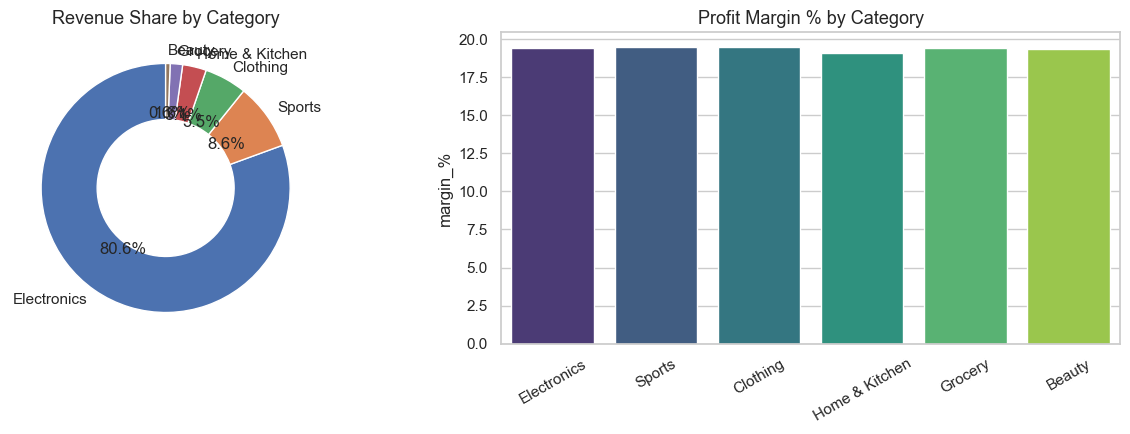

,revenue,profit,orders,margin_%,aov
category,,,,,
Electronics,3.134271e+09,609005443.5,85110,19.4,36826.1
Sports,3.363374e+08,65435073.8,135462,19.5,2482.9
Clothing,2.142378e+08,41721617.9,59336,19.5,3610.6
Home & Kitchen,1.199671e+08,22908869.7,69594,19.1,1723.8
Grocery,6.258190e+07,12161406.8,51904,19.4,1205.7
Beauty,2.246434e+07,4345074.7,38524,19.3,583.1


In [14]:
cat = delivered.groupby("category").agg(revenue=("sales_amount", "sum"), profit=("profit", "sum"), orders=("order_id", "count"))
cat["margin_%"] = cat["profit"] / cat["revenue"] * 100
cat["aov"] = cat["revenue"] / cat["orders"]
cat = cat.sort_values("revenue", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].pie(cat["revenue"], labels=cat.index, autopct="%1.1f%%", startangle=90, wedgeprops={"width": .45})
axes[0].set_title("Revenue Share by Category")
sns.barplot(x=cat.index, y=cat["margin_%"], ax=axes[1], palette="viridis")
axes[1].set_title("Profit Margin % by Category"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=30)
save("06_category_performance")
cat.round(1)

### 4.5 Pareto analysis (80/20 rule)

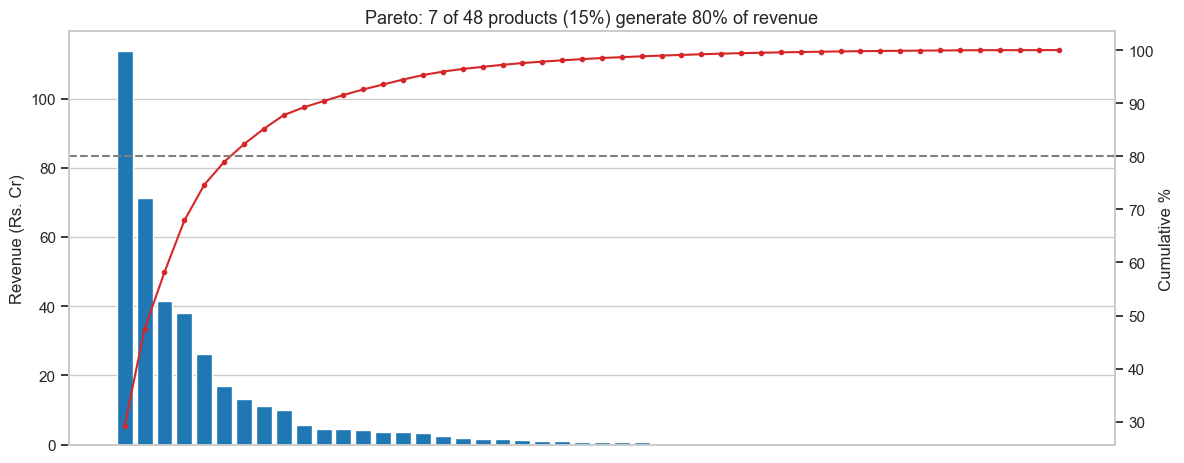

7 of 48 products make 80% of revenue


In [15]:
p = prod.sort_values("revenue", ascending=False).reset_index(drop=True)
p["cum_%"] = p["revenue"].cumsum() / p["revenue"].sum() * 100
n80 = (p["cum_%"] <= 80).sum() + 1
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.bar(range(len(p)), p["revenue"]/1e7, color="#1f77b4"); ax.set_ylabel("Revenue (Rs. Cr)")
ax2 = ax.twinx(); ax2.plot(range(len(p)), p["cum_%"], color="#d62728", marker="o", ms=3); ax2.set_ylabel("Cumulative %")
ax2.axhline(80, color="grey", ls="--"); ax2.grid(False)
ax.set_title(f"Pareto: {n80} of {len(p)} products ({n80/len(p)*100:.0f}%) generate 80% of revenue")
ax.set_xticks([])
save("07_pareto")
print(f"{n80} of {len(p)} products make 80% of revenue")

### 4.6 Discounts vs profitability

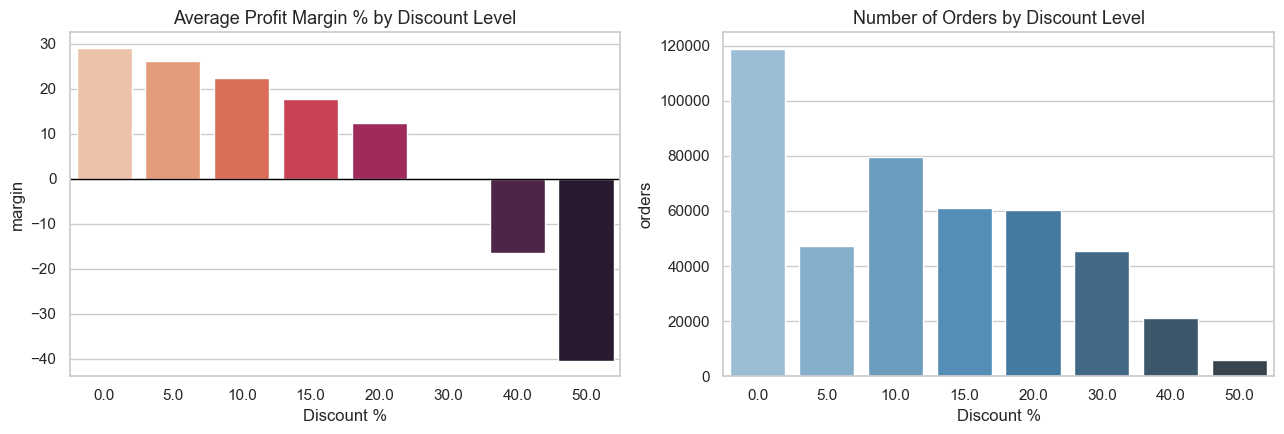

Loss-making orders: 57,648 (13.1%), total loss Rs. 552.3 Lakh
Share of loss-making orders by discount level (%):
discount_pct
0.0       1.0
5.0       0.0
10.0      0.0
15.0      0.0
20.0     16.8
30.0     50.1
40.0     83.3
50.0    100.0
Name: loss, dtype: float64


In [16]:
disc = delivered.groupby("discount_pct").agg(orders=("order_id", "count"), margin=("profit_margin_%", "mean"),
                                             avg_qty=("quantity", "mean")).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=disc, x="discount_pct", y="margin", ax=axes[0], palette="rocket_r")
axes[0].set_title("Average Profit Margin % by Discount Level"); axes[0].set_xlabel("Discount %")
axes[0].axhline(0, color="black", lw=1)
sns.barplot(data=disc, x="discount_pct", y="orders", ax=axes[1], palette="Blues_d")
axes[1].set_title("Number of Orders by Discount Level"); axes[1].set_xlabel("Discount %")
save("08_discount_vs_margin")

loss = delivered[delivered["profit"] < 0]
print(f"Loss-making orders: {len(loss):,} ({len(loss)/len(delivered)*100:.1f}%), total loss Rs. {abs(loss['profit'].sum())/1e5:,.1f} Lakh")
print("Share of loss-making orders by discount level (%):")
print((delivered.assign(loss=delivered["profit"] < 0).groupby("discount_pct")["loss"].mean()*100).round(1))

### 4.7 Geography, payments and customers

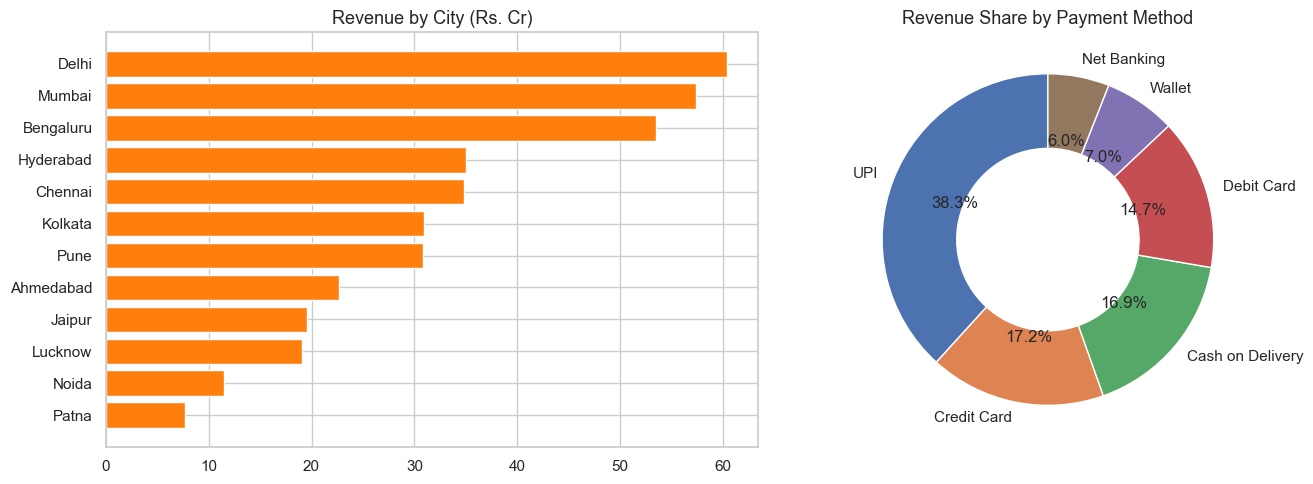

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
city = delivered[delivered.city != "Unknown"].groupby("city")["sales_amount"].sum().sort_values() / 1e7
axes[0].barh(city.index, city.values, color="#ff7f0e"); axes[0].set_title("Revenue by City (Rs. Cr)")
pay = delivered[delivered.payment_method != "Unknown"].groupby("payment_method")["sales_amount"].sum().sort_values(ascending=False)
axes[1].pie(pay, labels=pay.index, autopct="%1.1f%%", startangle=90, wedgeprops={"width": .45})
axes[1].set_title("Revenue Share by Payment Method")
save("09_city_payment")

In [18]:
seg = delivered[delivered.customer_segment != "Unknown"].groupby("customer_segment").agg(
    orders=("order_id", "count"), revenue=("sales_amount", "sum"), aov=("sales_amount", "mean"))
print(seg.round(1))

cust = delivered.groupby("customer_id")["sales_amount"].agg(["count", "sum"])
print(f"\nAvg orders per customer: {cust['count'].mean():.1f} | top 10% customers = "
      f"{cust['sum'].nlargest(int(len(cust)*.1)).sum()/cust['sum'].sum()*100:.1f}% of revenue")

store = delivered.groupby("store_type")["sales_amount"].sum()
print("\nOnline vs Offline revenue share %:"); print((store/store.sum()*100).round(1))

                  orders       revenue     aov
customer_segment                              
New                85318  7.530329e+08  8826.2
Premium            85140  7.526569e+08  8840.2
Regular           256078  2.266532e+09  8850.9

Avg orders per customer: 7.3 | top 10% customers = 30.8% of revenue

Online vs Offline revenue share %:
store_type
Offline    35.2
Online     64.8
Name: sales_amount, dtype: float64


### 4.8 Returns and cancellations

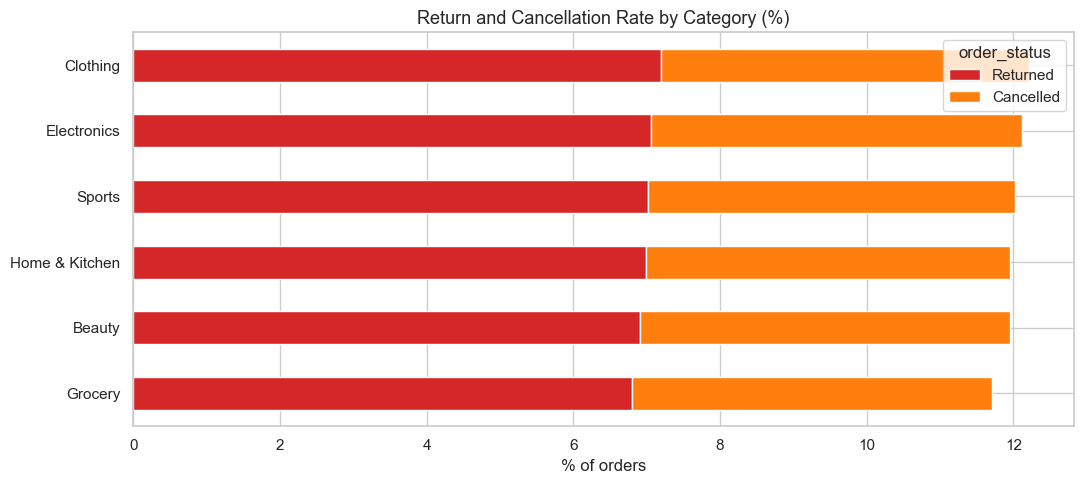

Revenue lost to returns + cancellations: Rs. 54.44 Cr (12.3% of gross order value)

Average rating by status (rated orders only):
order_status
Cancelled    3.94
Delivered    3.94
Returned     3.94
Name: rating, dtype: float64


In [19]:
status = pd.crosstab(df["category"], df["order_status"], normalize="index") * 100
ax = status[["Returned", "Cancelled"]].sort_values("Returned").plot(kind="barh", stacked=True, color=["#d62728", "#ff7f0e"])
ax.set_title("Return and Cancellation Rate by Category (%)"); ax.set_ylabel(""); ax.set_xlabel("% of orders")
save("10_returns_cancellations")

lost = df[df.order_status != "Delivered"]["sales_amount"].sum()
print(f"Revenue lost to returns + cancellations: Rs. {lost/1e7:.2f} Cr "
      f"({lost/df['sales_amount'].sum()*100:.1f}% of gross order value)")
print("\nAverage rating by status (rated orders only):")
print(df.groupby("order_status")["rating"].mean().round(2))

### 4.9 Correlation

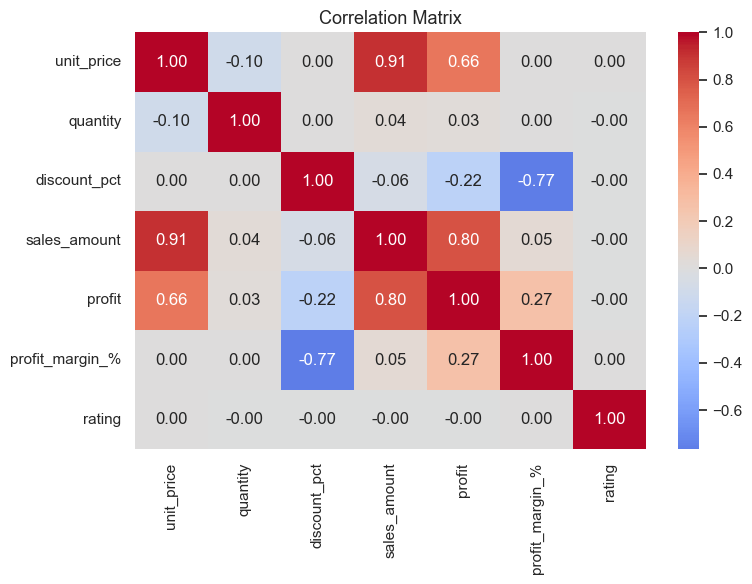

In [20]:
num = delivered[["unit_price", "quantity", "discount_pct", "sales_amount", "profit", "profit_margin_%", "rating"]]
plt.figure(figsize=(8, 6))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
save("11_correlation")

## 5. Key Insights

| # | Finding | Evidence |
|---|---------|----------|
| 1 | **Strong festive seasonality** | Oct, Nov and Dec run at ~1.46, 1.44 and 1.36 times the average month; Apr-Jun is the slump at ~0.75 |
| 2 | **Steady growth** | Revenue grew from Rs. 116.7 Cr (2023) to Rs. 128.9 Cr (2024, +10.5%) to Rs. 143.4 Cr (2025, +11.2%) |
| 3 | **Weekends sell more** | Average daily revenue is ~25% higher on Sat/Sun |
| 4 | **Electronics dominates revenue** | ~80% of revenue from 85k orders, because its average order value is ~Rs. 36.8k vs Rs. 0.6k-3.6k elsewhere |
| 5 | **Volume leader is not the revenue leader** | Sports has the most orders (135k) but only ~9% of revenue |
| 6 | **Highly concentrated** | 7 of 48 products generate 80% of revenue; Tablet and Smart Watch alone are ~47% |
| 7 | **Deep discounts destroy profit** | Margin falls from 29% (no discount) to 0% at 30% off and -40% at 50% off; 13% of delivered orders are loss-making, all at 20%+ discounts |
| 8 | **Discounts do not lift quantity** | Average quantity per order stays ~2.3 at every discount level |
| 9 | **Digital payments lead** | UPI contributes ~38% of revenue; online is ~65% of revenue |
| 10 | **Top metros** | Delhi, Mumbai and Bengaluru are the top three cities |
| 11 | **Leakage from returns/cancellations** | ~12% of gross order value (Rs. 54 Cr) is lost |

## 6. Recommendations
1. **Stock up early for Oct-Dec** and run inventory/marketing pushes from September; plan lean operations in Apr-Jun.
2. **Cap discounts at 15-20%.** Orders at 30%+ off earn zero or negative margin and do not increase units sold.
3. **Protect top sellers** (Tablet, Smart Watch, Smartphone): avoid stock-outs and negotiate better supplier terms.
4. **Weekend campaigns** (flash deals, delivery promos) to capitalise on the ~25% weekend uplift.
5. **Investigate the ~7% return rate**, especially for high-value Electronics where each return is costly.

## 7. Limitations
* The dataset is **synthetic**, so patterns (seasonality, discount effect) reflect how it was generated, not a real company. The same technique applies unchanged to real data.
* Ratings do not vary by order status and all categories share the same seasonal shape, which would be unusual in real data.
* `sales_amount` and `profit` were taken as recorded; they were not recomputed after quantity outliers were imputed.